# ML441 Assignment 4: Ensemble Learning for Network Intrusion Classification

Experiments for the Assignment 4 report. Results are cached in `output/`, and
`ML441_EXPERIMENT_MODE=smoke` runs a 10% subset.

## 0.1 Environment and reproducibility

Sets seed 21 and records package versions. `cuml-cu12` serves only the tie diagnostic of Section
1.4.

In [1]:
import copy
import hashlib
import importlib.metadata as metadata
import itertools
import json
import os
import platform
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tabm
import torch
import torch.nn.functional as F
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from sklearn.base import BaseEstimator, ClassifierMixin, TransformerMixin, clone
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    FunctionTransformer, OneHotEncoder, OrdinalEncoder, QuantileTransformer, RobustScaler, StandardScaler,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.validation import check_is_fitted

SMOKE = os.environ.get("ML441_EXPERIMENT_MODE", "full") == "smoke"
RANDOM_STATE = 21
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

A2_DIR = Path("../Assignment2")
DATA_PATH = A2_DIR / "networkTraffic.csv"
FEATURES_PATH = A2_DIR / "features.csv"
A2_OUTPUT_DIR = A2_DIR / "output"
OUTPUT_DIR = Path("output/smoke" if SMOKE else "output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PACKAGES = [
    "numpy", "pandas", "scipy", "scikit-learn", "matplotlib",
    "torch", "tabm", "rtdl_num_embeddings", "cuml-cu12",
]
environment = pd.DataFrame(
    [("python", sys.version.split()[0]), ("platform", platform.platform())]
    + [(package, metadata.version(package)) for package in PACKAGES]
    + [
        ("cuda_runtime", torch.version.cuda),
        ("gpu", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "none"),
        ("random_seed", RANDOM_STATE),
    ],
    columns=["component", "value"],
)
environment.to_csv(OUTPUT_DIR / "ass4_environment.csv", index=False)
print(f"Experiment mode: {'smoke' if SMOKE else 'full'}")
display(environment)

Experiment mode: full


,component,value
0,python,3.12.3
1,platform,Linux-6.18.33.2-microsoft-standard-WSL2-x86_64...
2,numpy,2.4.6
3,pandas,3.0.3
4,scipy,1.18.1
5,scikit-learn,1.9.0
6,matplotlib,3.11.1
7,torch,2.13.0+cu129
8,tabm,0.0.3
9,rtdl_num_embeddings,0.0.12


## 0.2 Data loading and target labels

Loads the Assignment 2 data and checks its SHA-256 digest. Target codes are decoded with the
mapping Assignment 2 derived from the published UNSW-NB15 class counts, and the cell checks that
the counts still match.

In [2]:
for path in (DATA_PATH, FEATURES_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Required input not found: {path.resolve()}")

data_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
a2_provenance = pd.read_csv(A2_OUTPUT_DIR / "ass2_input_provenance.csv").set_index("input_file")
if data_sha256 != a2_provenance.loc[DATA_PATH.name, "sha256"]:
    raise ValueError("networkTraffic.csv differs from the file Assignment 2 modelled.")

raw_df = pd.read_csv(DATA_PATH, na_values=["?"])
TARGET_COLUMN = raw_df.columns[-1]
NOMINAL_COLUMNS = ["proto", "state", "service"]
if raw_df.shape[1] - 1 != 43 or TARGET_COLUMN != "attack_cat":
    raise ValueError("Expected 43 descriptive features followed by the attack_cat target.")

# Assignment 2 established this code-to-name mapping from exact published class counts.
class_mapping = pd.read_csv(A2_OUTPUT_DIR / "ass2_class_mapping.csv")
CLASS_NAME_BY_CODE = dict(zip(class_mapping["attack_code"], class_mapping["attack_class"]))
observed_counts = raw_df[TARGET_COLUMN].dropna().astype(int).value_counts()
expected_counts = class_mapping.set_index("attack_code")["observed_count"]
if not observed_counts.sort_index().equals(expected_counts.sort_index()):
    raise ValueError("Target code counts do not match the Assignment 2 class mapping.")
CLASS_ORDER = [CLASS_NAME_BY_CODE[code] for code in sorted(CLASS_NAME_BY_CODE)]

analysis_df = raw_df.dropna(subset=[TARGET_COLUMN]).copy()
analysis_df[TARGET_COLUMN] = analysis_df[TARGET_COLUMN].astype(int).map(CLASS_NAME_BY_CODE)
X = analysis_df.drop(columns=["id", TARGET_COLUMN])
y = analysis_df[TARGET_COLUMN]
NUMERIC_COLUMNS = X.select_dtypes(include=np.number).columns.tolist()
predictor_groups = pd.util.hash_pandas_object(X, index=False).rename("predictor_group")

assert set(NUMERIC_COLUMNS) | set(NOMINAL_COLUMNS) == set(X.columns)
assert not set(NUMERIC_COLUMNS) & set(NOMINAL_COLUMNS)
print(f"Rows: {len(analysis_df):,} (missing targets removed: {len(raw_df) - len(analysis_df):,})")
print(f"Predictors: {X.shape[1]} ({len(NUMERIC_COLUMNS)} numeric, {len(NOMINAL_COLUMNS)} nominal)")
print(f"Dataset SHA-256 matches Assignment 2: {data_sha256[:16]}...")
display(class_mapping[["attack_code", "attack_class", "observed_count"]])

Rows: 257,673 (missing targets removed: 0)
Predictors: 42 (39 numeric, 3 nominal)
Dataset SHA-256 matches Assignment 2: acde2c646b55c9c6...


,attack_code,attack_class,observed_count
0,0,Normal,93000
1,1,Reconnaissance,13987
2,2,Backdoor,2329
3,3,DoS,16353
4,4,Exploits,44525
5,5,Analysis,2677
6,6,Fuzzers,24246
7,7,Worms,174
8,8,Shellcode,1511
9,9,Generic,58871


## 0.3 Label conflicts

Counts groups of identical predictor vectors with conflicting labels (report Table II). Every
fold below groups identical predictor vectors, which keeps exact copies of a test row out of
training whether or not their labels conflict.

In [3]:
label_groups = pd.DataFrame({"group": predictor_groups.to_numpy(), "target": y.to_numpy()})
labels_per_group = label_groups.groupby("group")["target"].transform("nunique")
label_conflict = pd.DataFrame(
    {
        "rows": y.value_counts().reindex(CLASS_ORDER),
        "share_in_conflicting_groups": (
            labels_per_group.gt(1).groupby(label_groups["target"]).mean().reindex(CLASS_ORDER)
        ),
    }
)
label_conflict.index.name = "attack_class"
label_conflict.to_csv(OUTPUT_DIR / "ass4_label_conflicts.csv")
print(f"Rows in label-conflicting groups: {labels_per_group.gt(1).mean():.1%}")
display(label_conflict.round(3))


Rows in label-conflicting groups: 15.7%


,rows,share_in_conflicting_groups
attack_class,,
Normal,93000,0.010
Reconnaissance,13987,0.161
Backdoor,2329,0.849
DoS,16353,0.774
Exploits,44525,0.371
Analysis,2677,0.770
Fuzzers,24246,0.149
Worms,174,0.086
Shellcode,1511,0.009


## 0.4 Preprocessing reused from Assignment 2

Defines `TrafficPreprocessor`, copied unchanged from Assignment 2. It encodes missing nominal
values as a `__missing__` level, one-hot encodes the nominal features, and optionally scales
numeric features, groups rare levels, prunes near-duplicate numeric features and keeps the 30
features with the largest ANOVA F statistics. k-NN needs scaling and the tree does not. TabM
uses its own preprocessing (Section 3.1).

In [4]:
class TrafficPreprocessor(BaseEstimator, TransformerMixin):
    '''Fold-fitted preprocessing used directly by the two notebook pipelines.'''

    def __init__(
        self,
        numeric_columns,
        nominal_columns,
        *,
        scaling="standard",
        min_frequency=None,
        correlation_threshold=0.995,
        selector_k=None,
        missing_label="__missing__",
    ):
        self.numeric_columns = numeric_columns
        self.nominal_columns = nominal_columns
        self.scaling = scaling
        self.min_frequency = min_frequency
        self.correlation_threshold = correlation_threshold
        self.selector_k = selector_k
        self.missing_label = missing_label

    @staticmethod
    def _encoder(min_frequency):
        handle_unknown = "infrequent_if_exist" if min_frequency is not None else "ignore"
        try:
            return OneHotEncoder(
                handle_unknown=handle_unknown,
                min_frequency=min_frequency,
                sparse_output=False,
                dtype=np.float32,
            )
        except TypeError:  # Compatibility with older scikit-learn releases.
            return OneHotEncoder(
                handle_unknown=handle_unknown,
                min_frequency=min_frequency,
                sparse=False,
                dtype=np.float32,
            )

    def _validate_frame(self, frame):
        if not isinstance(frame, pd.DataFrame):
            raise TypeError("TrafficPreprocessor requires a pandas DataFrame.")
        required = set(self.numeric_columns) | set(self.nominal_columns)
        missing = sorted(required.difference(frame.columns))
        if missing:
            raise KeyError(f"Missing preprocessing columns: {missing}")

    def fit(self, frame, target=None):
        self._validate_frame(frame)
        if self.scaling not in {None, "standard", "robust"}:
            raise ValueError("scaling must be None, 'standard', or 'robust'.")
        if self.correlation_threshold is not None and not (
            0 <= self.correlation_threshold <= 1
        ):
            raise ValueError("correlation_threshold must be between 0 and 1, or None.")

        numeric = frame.loc[:, self.numeric_columns]
        if numeric.isna().to_numpy().any():
            raise ValueError("Numeric predictors contain unexpected missing values.")

        kept_numeric = list(self.numeric_columns)
        dropped_numeric = []
        if self.correlation_threshold is not None and len(kept_numeric) > 1:
            absolute_correlation = numeric.corr().abs()
            kept_numeric = []
            for column in self.numeric_columns:
                if any(
                    absolute_correlation.loc[column, keeper]
                    >= self.correlation_threshold
                    for keeper in kept_numeric
                ):
                    dropped_numeric.append(column)
                else:
                    kept_numeric.append(column)

        self.kept_numeric_features_ = kept_numeric
        self.dropped_numeric_features_ = dropped_numeric
        numeric_values = frame.loc[:, kept_numeric].to_numpy(dtype=np.float32)
        if self.scaling == "standard":
            self.scaler_ = StandardScaler().fit(numeric_values)
        elif self.scaling == "robust":
            self.scaler_ = RobustScaler().fit(numeric_values)
        else:
            self.scaler_ = None

        self.nominal_imputer_ = SimpleImputer(
            strategy="constant",
            fill_value=self.missing_label,
            keep_empty_features=True,
        )
        nominal_imputed = self.nominal_imputer_.fit_transform(
            frame.loc[:, self.nominal_columns]
        )
        self.categorical_encoder_ = self._encoder(self.min_frequency)
        nominal_encoded = self.categorical_encoder_.fit_transform(nominal_imputed)
        numeric_transformed = (
            self.scaler_.transform(numeric_values)
            if self.scaler_ is not None
            else numeric_values
        )
        combined = np.hstack(
            [
                np.asarray(numeric_transformed),
                np.asarray(nominal_encoded),
            ]
        ).astype(np.float32, copy=False)
        feature_names = np.concatenate(
            [
                np.asarray(self.kept_numeric_features_, dtype=object),
                self.categorical_encoder_.get_feature_names_out(self.nominal_columns),
            ]
        )

        if self.selector_k is None:
            self.selector_ = None
            self.feature_names_out_ = feature_names
        else:
            if target is None:
                raise ValueError("target is required when selector_k is enabled.")
            selected_k = min(int(self.selector_k), combined.shape[1])
            if selected_k < 1:
                raise ValueError("selector_k must be at least 1 or None.")
            self.selector_ = SelectKBest(score_func=f_classif, k=selected_k).fit(
                combined, target
            )
            self.feature_names_out_ = feature_names[self.selector_.get_support()]

        self.n_features_out_ = len(self.feature_names_out_)
        return self

    def transform(self, frame):
        check_is_fitted(
            self,
            ["kept_numeric_features_", "categorical_encoder_", "n_features_out_"],
        )
        self._validate_frame(frame)
        numeric_values = frame.loc[:, self.kept_numeric_features_].to_numpy(
            dtype=np.float32
        )
        if self.scaler_ is not None:
            numeric_values = self.scaler_.transform(numeric_values)
        nominal_imputed = self.nominal_imputer_.transform(
            frame.loc[:, self.nominal_columns]
        )
        nominal_encoded = self.categorical_encoder_.transform(nominal_imputed)
        combined = np.hstack(
            [
                np.asarray(numeric_values),
                np.asarray(nominal_encoded),
            ]
        ).astype(np.float32, copy=False)
        return (
            self.selector_.transform(combined)
            if self.selector_ is not None
            else combined
        )

    def get_feature_names_out(self, input_features=None):
        check_is_fitted(self, "feature_names_out_")
        return np.asarray(self.feature_names_out_, dtype=object)

## 0.5 Outer folds shared with Assignment 2

Rebuilds the grouped outer folds and asserts that they match Assignment 2.

In [5]:
OUTER_FOLDS = 5
INNER_FOLDS = 3

outer_cv = StratifiedGroupKFold(n_splits=OUTER_FOLDS, shuffle=True, random_state=RANDOM_STATE)
outer_fold = pd.Series(0, index=X.index, name="outer_fold")
for fold, (_, test_positions) in enumerate(outer_cv.split(X, y, predictor_groups), start=1):
    outer_fold.iloc[test_positions] = fold
assert outer_fold.gt(0).all(), "Every row must belong to exactly one outer test fold."
assert predictor_groups.groupby(outer_fold.to_numpy()).unique().explode().is_unique, (
    "A predictor group was split across outer folds."
)

for a2_model in ("knn", "tree"):
    a2_folds = pd.read_csv(
        A2_OUTPUT_DIR / f"ass2_{a2_model}_oof_predictions_full.csv",
        usecols=["source_index", "outer_fold"],
    ).set_index("source_index")["outer_fold"]
    mismatched = int((a2_folds.reindex(X.index) != outer_fold).sum())
    assert mismatched == 0, f"{mismatched:,} rows differ from the A2 {a2_model} folds."
print("Outer folds match Assignment 2 exactly for both baseline models.")

outer_fold.rename_axis("source_index").to_csv(OUTPUT_DIR / "ass4_outer_folds.csv")
fold_summary = pd.crosstab(outer_fold, y).reindex(columns=CLASS_ORDER)
fold_summary["total"] = fold_summary.sum(axis=1)
display(fold_summary)

if SMOKE:
    # Keep every tenth predictor group (about 10% of rows) so a smoke run exercises every cell in minutes.
    keep = (predictor_groups % 10 == 0).to_numpy()
    X, y, predictor_groups, outer_fold = X[keep], y[keep], predictor_groups[keep], outer_fold[keep]
    print(f"Smoke mode: {len(X):,} rows kept")
FOLDS = range(1, OUTER_FOLDS + 1)

Outer folds match Assignment 2 exactly for both baseline models.


attack_cat,Normal,Reconnaissance,Backdoor,DoS,Exploits,Analysis,Fuzzers,Worms,Shellcode,Generic,total
outer_fold,,,,,,,,,,,
1,18600,2797,466,3271,8905,536,4849,35,302,11774,51535
2,18600,2797,465,3271,8905,535,4849,35,302,11775,51534
3,18600,2797,466,3270,8905,536,4850,35,302,11774,51535
4,18600,2798,466,3271,8905,535,4849,34,303,11774,51535
5,18600,2798,466,3270,8905,535,4849,35,302,11774,51534


## Questions set before evaluation

The questions, grids and predictions below were fixed **before** any ensemble was trained or
evaluated.

**TabM.** The score is the mean macro F1 of grouped 3-fold inner cross-validation on each
outer-train fold. Stage 1 searches capacity at *k* = 32, and stage 2 changes one factor from the
stage-1 selection.

| # | Question | Grid | Prediction |
|---|---|---|---|
| Q1 | How much does ensemble size improve macro F1 over a single MLP? | *k* ∈ {1, 4, 8, 32} | Most of the gain arrives by *k* = 8. |
| Q2 | Does class-weighted cross-entropy raise minority-class F1 (Worms, Shellcode) without hurting the majority classes? | unweighted, balanced weights | Minority recall rises, but precision on Normal and Generic falls. |
| Q3 | Do members trained on **different** minibatches (closer to bagging) beat members sharing one batch? | shared, distinct | Little difference: weight scaling already supplies the diversity. |
| Q4 | Which capacity suits data with label conflicts; does it favour stronger regularisation? | width {256, 512} × depth {2, 3} × dropout {0, 0.1, 0.2} × learning rate {1e-3, 2e-3} | Dropout > 0 wins; capacity matters little. |

**Stacking.** The meta-learner is tuned by grouped 3-fold cross-validation on all rows of
each outer-train fold, over representation {probabilities, log-probabilities, one-hot labels}
× C {0.01, 0.1, 1, 10} × class weight {none, balanced}.

| # | Question | Prediction |
|---|---|---|
| Q5 | Does the learned meta-learner (S2) beat soft voting over the same three learners (V2)? | Yes, slightly: soft voting cannot down-weight the weak k-NN. |
| Q6 | Does adding TabM (S2 against S1) add useful diversity? Measured by score and by base-learner error correlation. | Yes: TabM's errors correlate less with the tree's than k-NN's do. |
| Q7 | Does the meta-learner learn to trust k-NN on DoS and Analysis, where k-NN beat the tree in Assignment 2? | Yes: k-NN's own-class coefficients are largest for those two classes. |
| Q8 | Which meta-feature representation works best, and why? | Probabilities or log-probabilities; one-hot labels discard confidence. |

**Class-specific performance.**

| # | Question | Prediction |
|---|---|---|
| Q9 | How do Backdoor, DoS and Analysis F1 change relative to the earlier tree? | Gains are limited and occur mainly on the other named attack classes. |

Five paired folds cannot give a two-sided Wilcoxon *p* below 0.0625, so results report mean ±
standard deviation, the paired differences and the Nadeau–Bengio corrected resampled *t*-test.

**Revision after the first run (17 October).** Run 1 scored TabM on one grouped 20% hold-out and
tuned the meta-learner on 30,000 rows. Candidate differences were within hold-out noise, so the
protocol above replaced run 1, the Assignment 2 models were re-tuned (Section 1.5) and the final
TabM became a five-seed average on all rows. The grids and predictions were kept. The revised
analysis also added a Holm adjustment of the corrected-test *p*-values across the 11
comparisons. Run 1 results are in `output/run1_holdout_tuning/`.

# Phase 1: Assignment 2 baselines as stacking inputs

Rebuilds each baseline from its Assignment 2 parameters for each outer fold.

## 1.1 Out-of-fold probabilities

Defines the out-of-fold loop for meta-learner inputs and outer-test predictions.

In [6]:
a2_selected = pd.read_csv(A2_OUTPUT_DIR / "ass2_selected_parameters_full.csv")
A2_MODEL_NAMES = {"knn": "k-NN", "tree": "Decision tree"}
INNER_CV = StratifiedGroupKFold(n_splits=INNER_FOLDS, shuffle=True, random_state=RANDOM_STATE)


def build_baseline(model, fold):
    """Return Assignment 2's unfitted pipeline for `model` with the parameters it selected for `fold`."""
    selected = a2_selected[
        (a2_selected["model"] == A2_MODEL_NAMES[model]) & (a2_selected["outer_fold"] == fold)
    ]
    if len(selected) != 1:
        raise KeyError(f"Expected one A2 parameter row for {model} fold {fold}, found {len(selected)}.")
    if model == "knn":
        preprocess = TrafficPreprocessor(
            tuple(NUMERIC_COLUMNS), tuple(NOMINAL_COLUMNS), scaling="standard", correlation_threshold=0.995
        )
        estimator = KNeighborsClassifier(n_neighbors=5, algorithm="brute", n_jobs=-1)
    else:
        preprocess = TrafficPreprocessor(
            tuple(NUMERIC_COLUMNS), tuple(NOMINAL_COLUMNS), scaling=None, correlation_threshold=None
        )
        estimator = DecisionTreeClassifier(random_state=RANDOM_STATE)
    pipeline = Pipeline([("preprocess", preprocess), ("model", estimator)])
    return pipeline.set_params(**json.loads(selected["best_parameters"].iloc[0]))


def proba_frame(fitted, frame):
    """Class probabilities as a DataFrame aligned to `frame.index`, columns in CLASS_ORDER.

    A class absent from the training data gets probability 0 rather than a missing column.
    """
    proba = fitted.predict_proba(frame)
    return pd.DataFrame(proba, index=frame.index, columns=fitted.classes_).reindex(
        columns=CLASS_ORDER, fill_value=0.0
    )


def baseline_fit_predict(model, fold, params=None):
    """`fit_predict` for an Assignment 2 pipeline: A2's parameters for `fold`, optionally overridden by `params`."""
    return lambda X_fit, y_fit, groups_fit, X_predict: proba_frame(
        build_baseline(model, fold).set_params(**(params or {})).fit(X_fit, y_fit), X_predict
    )


def class_codes(labels):
    return torch.as_tensor(pd.Categorical(labels, CLASS_ORDER).codes, dtype=torch.long, device=DEVICE)


def out_of_fold_probabilities(fit_predict, fold):
    """Return (train_proba, test_proba) for outer fold `fold`.

    `fit_predict(X_fit, y_fit, groups_fit, X_predict)` fits a fresh model and returns class
    probabilities for `X_predict`.
    """
    train_mask = outer_fold.ne(fold)
    X_train, y_train, groups_train = X[train_mask], y[train_mask], predictor_groups[train_mask]
    parts = [
        fit_predict(X_train.iloc[fit], y_train.iloc[fit], groups_train.iloc[fit], X_train.iloc[held_out])
        for fit, held_out in INNER_CV.split(X_train, y_train, groups_train)
    ]
    train_proba = pd.concat(parts).loc[X_train.index]
    test_proba = fit_predict(X_train, y_train, groups_train, X[~train_mask])
    return train_proba, test_proba

## 1.2 Leakage test

Swaps in a memoriser and asserts uniform out-of-fold probabilities, with a positive control.

In [7]:
class GroupMemoriser(BaseEstimator, ClassifierMixin):
    """Predicts the memorised label for previously seen predictor vectors, uniform otherwise."""

    def fit(self, frame, target):
        self.classes_ = np.array(sorted(pd.unique(target)))
        self.memory_ = dict(zip(pd.util.hash_pandas_object(frame, index=False), target))
        return self

    def predict_proba(self, frame):
        proba = np.full((len(frame), len(self.classes_)), 1 / len(self.classes_))
        for row, key in enumerate(pd.util.hash_pandas_object(frame, index=False)):
            if key in self.memory_:
                proba[row] = self.classes_ == self.memory_[key]
        return proba


def memorise(X_fit, y_fit, groups_fit, X_predict):
    return proba_frame(GroupMemoriser().fit(X_fit, y_fit), X_predict)


memo_train, memo_test = out_of_fold_probabilities(memorise, 1)
train_rows, test_rows = outer_fold.index[outer_fold.ne(1)], outer_fold.index[outer_fold.eq(1)]
assert memo_train.index.equals(train_rows), "train_proba must have one row per outer-train row, in order."
assert memo_test.index.equals(test_rows), "test_proba must have one row per outer-test row, in order."
for name, table in (("train_proba", memo_train), ("test_proba", memo_test)):
    assert list(table.columns) == CLASS_ORDER, f"{name} columns must follow CLASS_ORDER."
    assert table.notna().all().all(), f"{name} has rows that were never predicted."
    assert np.allclose(table.sum(axis=1), 1), f"{name} rows must sum to 1."
    leaked = int((table.max(axis=1) > 0.5).sum())
    assert leaked == 0, f"{name}: {leaked:,} rows were predicted by a model trained on their group."
control = memorise(X.loc[train_rows], y.loc[train_rows], None, X.loc[train_rows])
assert control.max(axis=1).gt(0.5).all(), "Positive control failed: the memoriser should recognise its training rows."
print(f"Leakage test passed: {len(memo_train):,} train rows and {len(memo_test):,} test rows, none memorised.")

Leakage test passed: 206,138 train rows and 51,535 test rows, none memorised.


## 1.3 Run both baselines and verify against Assignment 2

Caches baseline probabilities (k-NN: about 11 minutes per fold on the CPU) and compares them
with Assignment 2.

In [8]:
PROBA_DIR = OUTPUT_DIR / "base_proba"
PROBA_DIR.mkdir(exist_ok=True)
train_proba, test_proba, oof_seconds = {}, {}, {}


def cached_oof(name, fold, fit_predict):
    """Load out-of-fold probabilities for (name, fold), computing and caching them on the first run."""
    paths = [PROBA_DIR / f"{name}_fold{fold}_{part}.parquet" for part in ("train", "test")]
    seconds_path = PROBA_DIR / f"{name}_fold{fold}_seconds.txt"
    if not seconds_path.exists():
        start = perf_counter()
        for table, path in zip(out_of_fold_probabilities(fit_predict, fold), paths):
            table.to_parquet(path)
        seconds_path.write_text(f"{perf_counter() - start:.1f}")  # written last, so it marks a complete fold
        print(f"{name} fold {fold}: {seconds_path.read_text()}s", flush=True)
    train_proba[name, fold], test_proba[name, fold] = (pd.read_parquet(path) for path in paths)
    oof_seconds[name, fold] = float(seconds_path.read_text())


for model in ("tree", "knn"):
    for fold in FOLDS:
        cached_oof(model, fold, baseline_fit_predict(model, fold))

ALPHABETICAL = sorted(CLASS_ORDER)


def predict_labels(proba):
    """Most probable class, ties broken alphabetically as scikit-learn's `predict` does."""
    return proba[ALPHABETICAL].idxmax(axis=1)


reproduction_rows = []
for model in ("tree", "knn"):
    a2_scores = pd.read_csv(A2_OUTPUT_DIR / f"ass2_{model}_fold_results_full.csv").set_index("outer_fold")
    a2_predicted = pd.read_csv(A2_OUTPUT_DIR / f"ass2_{model}_oof_predictions_full.csv", index_col="source_index")["predicted"]
    for fold in FOLDS:
        predicted = predict_labels(test_proba[model, fold])
        differs = predicted.ne(a2_predicted.loc[predicted.index]).to_numpy()
        top_two = np.sort(test_proba[model, fold].to_numpy(), axis=1)[:, -2:]
        reproduction_rows.append({
            "model": model,
            "outer_fold": fold,
            "macro_f1": f1_score(y.loc[predicted.index], predicted, average="macro"),
            "a2_macro_f1": a2_scores.loc[fold, "macro_f1"],
            "rows_differing": int(differs.sum()),
            "differing_rows_all_ties": bool(np.isclose(top_two[differs, 0], top_two[differs, 1]).all()),
        })
baseline_reproduction = pd.DataFrame(reproduction_rows)
baseline_reproduction["difference"] = baseline_reproduction["macro_f1"] - baseline_reproduction["a2_macro_f1"]
baseline_reproduction.to_csv(OUTPUT_DIR / "ass4_baseline_reproduction.csv", index=False)
display(baseline_reproduction)
if not SMOKE:
    assert baseline_reproduction["differing_rows_all_ties"].all(), "A baseline differs from Assignment 2 beyond exact ties."
    print(f"Both baselines reproduce Assignment 2; {baseline_reproduction['rows_differing'].sum()} predictions "
          "differ, all of them exact probability ties.")

,model,outer_fold,macro_f1,a2_macro_f1,rows_differing,differing_rows_all_ties,difference
0,tree,1,0.560766,0.560766,0,True,0.000000
1,tree,2,0.566128,0.566128,0,True,0.000000
2,tree,3,0.565096,0.565096,0,True,0.000000
3,tree,4,0.578169,0.578169,0,True,0.000000
4,tree,5,0.603001,0.603001,0,True,0.000000
5,knn,1,0.500787,0.500787,0,True,0.000000
6,knn,2,0.505012,0.505012,0,True,0.000000
7,knn,3,0.516022,0.516022,0,True,0.000000
8,knn,4,0.527275,0.527207,20,True,0.000068
9,knn,5,0.513872,0.513872,0,True,0.000000


Both baselines reproduce Assignment 2; 20 predictions differ, all of them exact probability ties.


**Finding.** The tree matches Assignment 2 on all folds and k-NN on four. Fold 4: 20 of 51,535
predictions differ, all exact DoS–Exploits ties.

## 1.4 Why the baseline k-NN stays on scikit-learn: neighbour ties

Counts fold-1 test rows with tied *k*-th and (*k*+1)-th neighbours and compares cuML with
scikit-learn.

In [9]:
tie_path = OUTPUT_DIR / "ass4_knn_tie_check.csv"
if not SMOKE and not tie_path.exists():
    from cuml.neighbors import KNeighborsClassifier as CumlKNeighborsClassifier

    fold, train_mask = 1, outer_fold.ne(1)
    knn = build_baseline("knn", fold).fit(X[train_mask], y[train_mask])
    Z_train, Z_test = knn[:-1].transform(X[train_mask]), knn[:-1].transform(X[~train_mask])
    k = knn[-1].n_neighbors
    distances, _ = knn[-1].kneighbors(Z_test, n_neighbors=k + 1)
    sklearn_pred = predict_labels(test_proba["knn", fold]).to_numpy()
    start = perf_counter()
    cuml_knn = CumlKNeighborsClassifier(n_neighbors=k, metric="manhattan", weights="distance")
    cuml_knn.fit(Z_train, pd.Categorical(y[train_mask], CLASS_ORDER).codes.astype(np.int32))
    cuml_pred = np.asarray(CLASS_ORDER)[np.asarray(cuml_knn.predict(Z_test)).astype(int)]
    truth = y[~train_mask]
    pd.DataFrame([{
        "outer_fold": fold,
        "k": k,
        "test_rows_with_boundary_tie": np.mean(distances[:, k - 1] == distances[:, k]),
        "cuml_sklearn_disagreement": np.mean(cuml_pred != sklearn_pred),
        "sklearn_macro_f1": f1_score(truth, sklearn_pred, average="macro"),
        "cuml_macro_f1": f1_score(truth, cuml_pred, average="macro"),
        "cuml_fit_predict_seconds": perf_counter() - start,
        "sklearn_oof_seconds_per_fit": oof_seconds["knn", fold] / (INNER_FOLDS + 1),
    }]).to_csv(tie_path, index=False)
if tie_path.exists():
    display(pd.read_csv(tie_path).T)

,0
outer_fold,1.000000
k,3.000000
test_rows_with_boundary_tie,0.421015
cuml_sklearn_disagreement,0.100572
sklearn_macro_f1,0.500787
cuml_macro_f1,0.492253
cuml_fit_predict_seconds,63.188047
sklearn_oof_seconds_per_fit,168.750000


**Finding.** On fold 1, 42.1% of test rows have tied 3rd and 4th neighbours. cuML's own
`predict` disagrees with scikit-learn on 10.1% of fold-one predictions (macro F1 0.492 against
0.501), partly because it breaks probability ties by class code. With alphabetical tie-breaking
on both sides, `scripts/knn_cpu_vs_gpu.py` finds 6.0–9.7% of labels changed across the five
folds (9.3% on fold 1), every one at a tie at the *k*-th distance (report Table I).

## 1.5 Revised baselines: full-scale tuning

Re-tunes the tree (256 of 1,728 settings) and k-NN (all 256 settings, GPU search) by grouped
3-fold inner cross-validation on all outer-train rows.

- The single-precision GPU search agrees with scikit-learn on 99.833% of fold-1 labels with the
  Assignment 2 settings (asserted in the next cell).

In [10]:
a2_domains = pd.read_csv(A2_OUTPUT_DIR / "ass2_search_domains_full.csv")
DOMAIN = {
    model: {row.parameter: json.loads(row.complete_domain_values_json) for row in group.itertuples()}
    for model, group in a2_domains.groupby("model")
}
TREE_CANDIDATES = 8 if SMOKE else 256
REVISED_DIR = OUTPUT_DIR / "revised_tuning"
REVISED_DIR.mkdir(exist_ok=True)


def gpu_neighbours(Z_train, Z_test, k, p, chunk=256):
    """The k nearest training rows of each test row, ordered by (distance, training index).

    Among rows tied at the k-th distance the lowest training index wins, so equal distances always
    resolve the same way; single-precision distances can still differ in the last bit across GPUs.
    """
    train = torch.as_tensor(Z_train, device=DEVICE)
    distances, indices = [], []
    for test in torch.as_tensor(Z_test, device=DEVICE).split(chunk):
        distance = torch.cdist(test, train, p=p, compute_mode="donot_use_mm_for_euclid_dist")
        kth = distance.topk(k, largest=False).values[:, -1:]
        closer, tied = distance < kth, distance == kth
        chosen = closer | (tied & (tied.cumsum(1) <= k - closer.sum(1, keepdim=True)))
        index = chosen.nonzero(as_tuple=True)[1].view(len(test), k)  # ascending training index
        nearest, order = distance.gather(1, index).sort(dim=1, stable=True)  # stable: ties keep index order
        distances.append(nearest)
        indices.append(index.gather(1, order))
    return torch.cat(distances), torch.cat(indices)


def knn_vote(distances, indices, train_codes, k, weights, index):
    """Class probabilities from the first k ordered neighbours, with scikit-learn's weighting rules."""
    d, neighbours = distances[:, :k], indices[:, :k]
    if weights == "distance":
        exact = d == 0  # scikit-learn: if any neighbour is at distance 0, only those neighbours vote
        w = torch.where(exact.any(1, keepdim=True), exact.float(), 1 / d)
    else:
        w = torch.ones_like(d)
    votes = torch.zeros(len(d), len(CLASS_ORDER), device=DEVICE).scatter_add_(1, train_codes[neighbours], w)
    return pd.DataFrame((votes / votes.sum(1, keepdim=True)).cpu().numpy(), index=index, columns=CLASS_ORDER)


def knn_preprocessor(params):
    preprocessing = {key.removeprefix("preprocess__"): value for key, value in params.items() if key.startswith("preprocess__")}
    return TrafficPreprocessor(tuple(NUMERIC_COLUMNS), tuple(NOMINAL_COLUMNS), **preprocessing)


def gpu_knn_fit_predict(params):
    """`fit_predict` for the GPU k-NN with Assignment 2's preprocessing and a full A2-style parameter set."""
    def fit_predict(X_fit, y_fit, groups_fit, X_predict):
        preprocess = knn_preprocessor(params)
        Z_fit = preprocess.fit_transform(X_fit, y_fit)
        k = params["model__n_neighbors"]
        distances, indices = gpu_neighbours(Z_fit, preprocess.transform(X_predict), k, params["model__p"])
        return knn_vote(distances, indices, class_codes(y_fit), k, params["model__weights"], X_predict.index)
    return fit_predict


# With A2's fold-1 parameters the GPU k-NN must match the scikit-learn baseline on almost every row.
a2_knn_params = json.loads(a2_selected.query("model == 'k-NN' and outer_fold == 1")["best_parameters"].iloc[0])
train_mask = outer_fold.ne(1)
gpu_labels = predict_labels(gpu_knn_fit_predict(a2_knn_params)(X[train_mask], y[train_mask], None, X[~train_mask]))
agreement = gpu_labels.eq(predict_labels(test_proba["knn", 1])).mean()
assert agreement > 0.995, f"GPU k-NN agrees with scikit-learn on only {agreement:.2%} of fold-1 labels."
print(f"GPU k-NN with A2's fold-1 parameters agrees with scikit-learn on {agreement:.3%} of labels.")


def tune_tree(fold):
    """Revised tree: randomised search over A2's tree domain, grouped 3-fold CV on all outer-train rows."""
    path = REVISED_DIR / f"tree_fold{fold}.csv"
    if not path.exists():
        start, train_mask = perf_counter(), outer_fold.ne(fold)
        search = RandomizedSearchCV(
            build_baseline("tree", fold), DOMAIN["Decision tree"], n_iter=TREE_CANDIDATES, scoring="f1_macro",
            cv=INNER_CV, n_jobs=-2, refit=False, random_state=RANDOM_STATE,
        ).fit(X[train_mask], y[train_mask], groups=predictor_groups[train_mask])
        results = pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]]
        results.assign(params=results["params"].map(json.dumps), seconds=perf_counter() - start).to_csv(path, index=False)
        print(f"tree fold {fold}: {perf_counter() - start:.0f}s", flush=True)
    return pd.read_csv(path).assign(outer_fold=fold)


KNN_DOMAIN = DOMAIN["k-NN"]
PREPROCESS_KEYS = [key for key in KNN_DOMAIN if key.startswith("preprocess__")]


def tune_knn(fold):
    """Revised k-NN: every setting of A2's k-NN domain, grouped 3-fold CV on all outer-train rows, on the GPU."""
    path = REVISED_DIR / f"knn_fold{fold}.csv"
    if not path.exists():
        start, train_mask = perf_counter(), outer_fold.ne(fold)
        X_train, y_train, groups_train = X[train_mask], y[train_mask], predictor_groups[train_mask]
        rows = []
        for split, (fit, held_out) in enumerate(INNER_CV.split(X_train, y_train, groups_train)):
            truth, codes = y_train.iloc[held_out], class_codes(y_train.iloc[fit])
            for values in itertools.product(*(KNN_DOMAIN[key] for key in PREPROCESS_KEYS)):
                preprocessing = dict(zip(PREPROCESS_KEYS, values))
                preprocess = knn_preprocessor(preprocessing)
                Z_fit = preprocess.fit_transform(X_train.iloc[fit], y_train.iloc[fit])
                Z_held = preprocess.transform(X_train.iloc[held_out])
                for p in KNN_DOMAIN["model__p"]:
                    distances, indices = gpu_neighbours(Z_fit, Z_held, max(KNN_DOMAIN["model__n_neighbors"]), p)
                    for k, weights in itertools.product(KNN_DOMAIN["model__n_neighbors"], KNN_DOMAIN["model__weights"]):
                        params = preprocessing | {"model__p": p, "model__n_neighbors": k, "model__weights": weights}
                        predicted = predict_labels(knn_vote(distances, indices, codes, k, weights, truth.index))
                        rows.append({"params": json.dumps(params), "macro_f1": f1_score(truth, predicted, average="macro")})
            print(f"knn fold {fold} inner split {split}: {perf_counter() - start:.0f}s", flush=True)
        table = pd.DataFrame(rows).groupby("params")["macro_f1"].agg(mean_test_score="mean", std_test_score="std")
        table.reset_index().assign(seconds=perf_counter() - start).to_csv(path, index=False)
    return pd.read_csv(path).assign(outer_fold=fold)


revised_tuning = {"tree": pd.concat([tune_tree(fold) for fold in FOLDS]), "knn": pd.concat([tune_knn(fold) for fold in FOLDS])}
revised_params = {
    (model, fold): json.loads(group.loc[group["mean_test_score"].idxmax(), "params"])
    for model, table in revised_tuning.items() for fold, group in table.groupby("outer_fold")
}
for fold in FOLDS:
    cached_oof("tree_r", fold, baseline_fit_predict("tree", fold, revised_params["tree", fold]))
    cached_oof("knn_r", fold, gpu_knn_fit_predict(revised_params["knn", fold]))

revised_selected = pd.DataFrame([
    {"model": model, "outer_fold": fold, "inner_macro_f1": group["mean_test_score"].max(), **revised_params[model, fold]}
    for model, table in revised_tuning.items() for fold, group in table.groupby("outer_fold")
])
revised_selected.to_csv(OUTPUT_DIR / "ass4_revised_selected.csv", index=False)
display(revised_selected)

/tmp/ipykernel_50830/2556048286.py:46: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  return torch.as_tensor(pd.Categorical(labels, CLASS_ORDER).codes, dtype=torch.long, device=DEVICE)


GPU k-NN with A2's fold-1 parameters agrees with scikit-learn on 99.833% of labels.


,model,outer_fold,inner_macro_f1,preprocess__min_frequency,model__min_samples_split,model__min_samples_leaf,model__max_features,model__max_depth,model__criterion,model__class_weight,model__ccp_alpha,preprocess__scaling,preprocess__correlation_threshold,preprocess__selector_k,model__p,model__n_neighbors,model__weights
0,tree,1,0.580881,NaN,2.0,1.0,NaN,24.0,gini,balanced,0.0000,NaN,NaN,NaN,NaN,NaN,NaN
1,tree,2,0.586043,50.0,10.0,1.0,NaN,16.0,entropy,balanced,0.0001,NaN,NaN,NaN,NaN,NaN,NaN
2,tree,3,0.583271,50.0,10.0,1.0,NaN,16.0,entropy,balanced,0.0001,NaN,NaN,NaN,NaN,NaN,NaN
3,tree,4,0.577531,50.0,10.0,1.0,NaN,16.0,entropy,balanced,0.0001,NaN,NaN,NaN,NaN,NaN,NaN
4,tree,5,0.586672,50.0,10.0,1.0,NaN,16.0,entropy,balanced,0.0001,NaN,NaN,NaN,NaN,NaN,NaN
5,knn,1,0.519436,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,robust,NaN,NaN,1.0,11.0,distance
6,knn,2,0.519804,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,robust,NaN,NaN,1.0,11.0,distance
7,knn,3,0.511185,50.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,robust,NaN,NaN,1.0,5.0,distance
8,knn,4,0.519160,50.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,robust,NaN,NaN,1.0,5.0,distance
9,knn,5,0.520273,50.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,robust,NaN,NaN,1.0,11.0,distance


**Findings.** The GPU search passes the agreement check above. Selected settings: report Table
V.

# Phase 2: The BatchEnsemble layer

Implements the shared-weight layer and checks it against `tabm.LinearBatchEnsemble`. The report
calls *k* the member count *M*.

In [11]:
class BatchEnsembleLinear(torch.nn.Module):
    """k linear layers sharing one weight matrix: member i computes s_i * (W (r_i * x_i)) + b_i."""

    def __init__(self, in_features, out_features, k):
        super().__init__()
        self.weight = torch.nn.Parameter(torch.empty(out_features, in_features))  # shared W
        self.r = torch.nn.Parameter(torch.ones(k, in_features))
        self.s = torch.nn.Parameter(torch.ones(k, out_features))
        self.bias = torch.nn.Parameter(torch.zeros(k, out_features))
        torch.nn.init.kaiming_uniform_(self.weight, a=5**0.5)

    def forward(self, x):
        """x has shape (batch, k, in_features); x[:, i] is member i's input."""
        return (x * self.r) @ self.weight.T * self.s + self.bias


reference = tabm.LinearBatchEnsemble(7, 5, k=4, scaling_init="random-signs")
layer = BatchEnsembleLinear(7, 5, k=4)
layer.load_state_dict(reference.state_dict())
x = torch.randn(3, 4, 7)
assert torch.allclose(layer(x), reference(x), atol=1e-6), "Hand-written layer differs from tabm.LinearBatchEnsemble."
for i in range(4):
    W_i = layer.s[i, :, None] * layer.weight * layer.r[i]
    assert torch.allclose(layer(x)[:, i], x[:, i] @ W_i.T + layer.bias[i], atol=1e-6)
print("BatchEnsembleLinear matches tabm.LinearBatchEnsemble and the explicit rank-one member weights.")

BatchEnsembleLinear matches tabm.LinearBatchEnsemble and the explicit rank-one member weights.


# Phase 3: TabM

## 3.1 Preprocessing, training and prediction

Defines the quantile-transform preprocessing, AdamW training with early stopping on inner macro
F1, and member-averaged prediction.

In [12]:
MISSING = "__missing__"
TABM_DEFAULTS = {
    "k": 32, "d_block": 512, "n_blocks": 3, "dropout": 0.1, "lr": 2e-3,
    "class_weight": False, "distinct_batches": False,
}
BATCH_SIZE, WEIGHT_DECAY = 512, 3e-4
MAX_EPOCHS, PATIENCE = (3, 2) if SMOKE else (80, 8)
SEEDS = 1 if SMOKE else 5
TABM_KEYS = list(TABM_DEFAULTS)


def tabm_encoder(fit_frame):
    """Fit TabM preprocessing on `fit_frame`; return (cat_cardinalities, encode) where encode(frame) -> GPU tensors."""
    quantile = QuantileTransformer(output_distribution="normal", random_state=RANDOM_STATE)
    quantile.fit(fit_frame[NUMERIC_COLUMNS])
    ordinal = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    ordinal.fit(fit_frame[NOMINAL_COLUMNS].fillna(MISSING))

    def encode(frame):
        numeric = quantile.transform(frame[NUMERIC_COLUMNS])
        nominal = ordinal.transform(frame[NOMINAL_COLUMNS].fillna(MISSING)) + 1  # 0 = level unseen in training
        return (
            torch.as_tensor(numeric, dtype=torch.float32, device=DEVICE),
            torch.as_tensor(nominal, dtype=torch.long, device=DEVICE),
        )

    return [len(categories) + 1 for categories in ordinal.categories_], encode


def ensemble_loss(logits, target, weight=None):
    """Mean of the members' own cross-entropies; logits (batch, k, classes), target (batch, k)."""
    return F.cross_entropy(logits.flatten(0, 1), target.flatten(), weight=weight)


@torch.no_grad()
def member_proba(model, numeric, nominal):
    """Each member's class probabilities, shape (rows, k, classes)."""
    model.eval()
    return torch.cat([
        model(n, c).softmax(-1) for n, c in zip(numeric.split(8192), nominal.split(8192))
    ]).cpu().numpy()


def tabm_data(X_fit, y_fit, X_val=None, y_val=None):
    """Encode a training split, and optionally a validation split, once; every model trained on it reuses the tensors."""
    cardinalities, encode = tabm_encoder(X_fit)
    data = {"cardinalities": cardinalities, "encode": encode, "train": (*encode(X_fit), class_codes(y_fit)), "val": None}
    if X_val is not None:
        data["val"] = (*encode(X_val), class_codes(y_val).cpu().numpy())
    return data


def train_tabm(data, params, epochs=MAX_EPOCHS, seed=RANDOM_STATE):
    """Train TabM on data["train"]; return (model, record).

    With validation data the model keeps its best epoch by validation macro F1 (early stopping)
    and the record holds the validation results. Without it, the model trains for exactly `epochs`.
    """
    params = TABM_DEFAULTS | params
    k = params["k"]
    numeric, nominal, target = data["train"]
    weight = None
    if params["class_weight"]:
        weight = len(target) / (len(CLASS_ORDER) * torch.bincount(target, minlength=len(CLASS_ORDER)).clamp(min=1))

    torch.manual_seed(seed)
    model = tabm.TabM.make(
        n_num_features=numeric.shape[1], cat_cardinalities=data["cardinalities"], d_out=len(CLASS_ORDER),
        k=k, d_block=params["d_block"], n_blocks=params["n_blocks"], dropout=params["dropout"],
    ).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=params["lr"], weight_decay=WEIGHT_DECAY)
    best_f1, best_epoch, start = -1.0, epochs, perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        # Column i of `order` is member i's row order: one shared permutation, or one per member.
        permutations = k if params["distinct_batches"] else 1
        order = torch.stack([torch.randperm(len(target), device=DEVICE) for _ in range(permutations)], dim=1)
        for rows in order.expand(-1, k).split(BATCH_SIZE):
            loss = ensemble_loss(model(numeric[rows], nominal[rows]), target[rows], weight)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
        if data["val"] is None:
            continue
        val_f1 = f1_score(data["val"][2], member_proba(model, *data["val"][:2]).mean(1).argmax(1), average="macro")
        if val_f1 > best_f1:
            best_f1, best_epoch, best_state = val_f1, epoch, copy.deepcopy(model.state_dict())
        elif epoch - best_epoch >= PATIENCE:
            break
    record = params | {"epochs": best_epoch, "seconds": perf_counter() - start}
    if data["val"] is None:
        return model, record

    model.load_state_dict(best_state)
    val_numeric, val_nominal, val_target = data["val"]
    val_members = member_proba(model, val_numeric, val_nominal)
    val_pred = val_members.mean(1).argmax(1)
    assert np.isclose(f1_score(val_target, val_pred, average="macro"), best_f1), "Best state was not restored."
    class_f1 = f1_score(val_target, val_pred, labels=range(len(CLASS_ORDER)), average=None, zero_division=0)
    record |= {
        "val_macro_f1": best_f1,
        "mean_member_f1": np.mean([f1_score(val_target, val_members[:, i].argmax(1), average="macro") for i in range(k)]),
    } | {f"val_f1_{name}": value for name, value in zip(CLASS_ORDER, class_f1)}
    return model, record

## 3.2 Tests: loss, single-batch overfitting and parameter cost

Tests the loss, a 64-row overfit and what *k* = 32 members add: scaling vectors, biases and
output heads.

In [13]:
logits = torch.randn(6, 4, len(CLASS_ORDER))
target = torch.randint(len(CLASS_ORDER), (6, 1)).expand(-1, 4)
per_member = torch.stack([F.cross_entropy(logits[:, i], target[:, i]) for i in range(4)])
assert torch.isclose(ensemble_loss(logits, target), per_member.mean())
assert torch.isclose(ensemble_loss(torch.zeros_like(logits), target), torch.tensor(np.log(len(CLASS_ORDER)), dtype=torch.float32))
averaged_loss = F.nll_loss(logits.softmax(-1).mean(1).log(), target[:, 0])
assert averaged_loss <= per_member.mean(), "Jensen: the averaged prediction's loss cannot exceed the mean member loss."
print(f"Toy batch: mean member loss {per_member.mean():.3f}, loss of the averaged prediction {averaged_loss:.3f}")

cardinalities, encode_all = tabm_encoder(X)
conflict_free = y.groupby(predictor_groups).transform("nunique").eq(1)
rows = X[conflict_free].sample(64, random_state=RANDOM_STATE).index
numeric, nominal = encode_all(X.loc[rows])
target = class_codes(y.loc[rows])
torch.manual_seed(RANDOM_STATE)
model = tabm.TabM.make(
    n_num_features=len(NUMERIC_COLUMNS), cat_cardinalities=cardinalities, d_out=len(CLASS_ORDER), k=4, dropout=0.0
).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-3)
model.train()
for _ in range(300):
    loss = ensemble_loss(model(numeric, nominal), target[:, None].expand(-1, 4))
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
train_accuracy = (member_proba(model, numeric, nominal).mean(1).argmax(1) == target.cpu().numpy()).mean()
assert train_accuracy == 1, f"A single batch was not overfitted (accuracy {train_accuracy:.3f})."
print(f"Single batch of 64 rows overfitted: accuracy {train_accuracy:.0%}, final loss {loss.item():.4f}")


def n_parameters(module):
    return sum(parameter.numel() for parameter in module.parameters())


size = {
    k: n_parameters(tabm.TabM.make(
        n_num_features=len(NUMERIC_COLUMNS), cat_cardinalities=cardinalities, d_out=len(CLASS_ORDER), k=k
    ))
    for k in (1, 32)
}
parameter_cost = pd.Series({
    "TabM, k = 1 (one MLP)": size[1],
    "TabM, k = 32": size[32],
    "32 independent MLPs": 32 * size[1],
}, name="parameters")
parameter_cost.to_csv(OUTPUT_DIR / "ass4_tabm_parameter_cost.csv")
display(parameter_cost.to_frame())

Toy batch: mean member loss 2.825, loss of the averaged prediction 2.508


Single batch of 64 rows overfitted: accuracy 100%, final loss 0.0000


,parameters
"TabM, k = 1 (one MLP)",635601
"TabM, k = 32",927776
32 independent MLPs,20339232


**Finding.** At *k* = 32, TabM has 927,776 parameters, 46% more than one MLP (report Section
III-E).

## 3.3 Tuning TabM (Q1–Q4)

Scores 24 capacity candidates at *k* = 32, then five one-factor variants, by grouped 3-fold
inner cross-validation.

In [14]:
CAPACITY_GRID = [
    {"d_block": width, "n_blocks": depth, "dropout": dropout, "lr": lr}
    for width in (256, 512) for depth in (2, 3) for dropout in (0.0, 0.1, 0.2) for lr in (1e-3, 2e-3)
][: 2 if SMOKE else None]
FOLLOW_UPS = [("Q1 ensemble size", {"k": k}) for k in (1, 4, 8)] + [
    ("Q2 class weights", {"class_weight": True}),
    ("Q3 distinct batches", {"distinct_batches": True}),
]
TUNING_DIR = OUTPUT_DIR / "tabm_tuning"
TUNING_DIR.mkdir(exist_ok=True)


def tune_tabm(fold):
    """Score every TabM candidate for one outer fold by grouped 3-fold CV on its outer-train rows."""
    path = TUNING_DIR / f"fold{fold}.csv"
    if path.exists():
        return pd.read_csv(path)
    train_mask = outer_fold.ne(fold)
    X_train, y_train, groups_train = X[train_mask], y[train_mask], predictor_groups[train_mask]
    splits = [
        tabm_data(X_train.iloc[fit], y_train.iloc[fit], X_train.iloc[held_out], y_train.iloc[held_out])
        for fit, held_out in INNER_CV.split(X_train, y_train, groups_train)
    ]

    def run(question, params):
        scores = pd.DataFrame([train_tabm(split, params)[1] for split in splits]).drop(columns=TABM_KEYS)
        record = TABM_DEFAULTS | params | scores.mean().to_dict() | {
            "val_macro_f1_std": scores["val_macro_f1"].std(),
            "seconds": scores["seconds"].sum(),
            "question": question,
            "params": json.dumps(params),
        }
        print(f"fold {fold} | {question} | {params}: {record['val_macro_f1']:.4f} ± {record['val_macro_f1_std']:.4f} "
              f"({record['epochs']:.0f} epochs, {record['seconds']:.0f}s)", flush=True)
        return record

    records = [run("Q4 capacity", params) for params in CAPACITY_GRID]
    best_capacity = json.loads(max(records, key=lambda record: record["val_macro_f1"])["params"])
    records += [run(question, best_capacity | change) for question, change in FOLLOW_UPS]
    table = pd.DataFrame(records).assign(outer_fold=fold)
    table.to_csv(path, index=False)
    return table


tabm_tuning = pd.concat([tune_tabm(fold) for fold in FOLDS], ignore_index=True)
tabm_tuning.to_csv(OUTPUT_DIR / "ass4_tabm_tuning.csv", index=False)
selected_rows = tabm_tuning.loc[tabm_tuning.groupby("outer_fold")["val_macro_f1"].idxmax()].set_index("outer_fold")
selected_tabm = {fold: (json.loads(row["params"]), max(1, round(row["epochs"]))) for fold, row in selected_rows.iterrows()}
selected_table = selected_rows[TABM_KEYS + ["question", "val_macro_f1", "val_macro_f1_std", "epochs"]]
selected_table.to_csv(OUTPUT_DIR / "ass4_tabm_selected.csv")
display(selected_table)

,k,d_block,n_blocks,dropout,lr,class_weight,distinct_batches,question,val_macro_f1,val_macro_f1_std,epochs
outer_fold,,,,,,,,,,,
1,32,256,3,0.1,0.002,False,False,Q4 capacity,0.536125,0.008715,24.000000
2,8,512,3,0.0,0.002,False,False,Q1 ensemble size,0.545481,0.005939,17.000000
3,32,256,3,0.0,0.002,False,False,Q4 capacity,0.545805,0.012997,28.000000
4,32,512,3,0.0,0.001,False,False,Q4 capacity,0.543873,0.004738,20.000000
5,8,512,3,0.0,0.002,False,False,Q1 ensemble size,0.546529,0.008220,13.333333


**Finding.** Every selected model has depth 3. Four folds select dropout 0, three keep *k* = 32
and two select *k* = 8 (report Table V).

## 3.4 TabM out-of-fold probabilities

Retrains each selected configuration for its mean best epoch as a five-seed average, without a
hold-out.

In [15]:
def tabm_fit_predict(params, epochs):
    """`fit_predict` for TabM: SEEDS models trained for `epochs` on all given rows, probabilities averaged."""
    def fit_predict(X_fit, y_fit, groups_fit, X_predict):
        data = tabm_data(X_fit, y_fit)
        numeric, nominal = data["encode"](X_predict)
        proba = np.mean([
            member_proba(train_tabm(data, params, epochs, seed)[0], numeric, nominal).mean(1)
            for seed in range(RANDOM_STATE, RANDOM_STATE + SEEDS)
        ], axis=0)
        return pd.DataFrame(proba, index=X_predict.index, columns=CLASS_ORDER)
    return fit_predict


for fold in FOLDS:
    cached_oof("tabm", fold, tabm_fit_predict(*selected_tabm[fold]))

**Finding.** Final TabM macro F1 was 0.525 (run 1: 0.549), with DoS recall 0.055 (report Section
V-D).

# Phase 4: Stacking

Builds the meta-features and the logistic-regression stacks S1 (revised k-NN and tree) and S2
(adding TabM), plus the soft vote V2.

In [16]:
def meta_features(proba, kind="proba"):
    """Meta-learner inputs from stacked probability blocks of len(CLASS_ORDER) columns per base learner."""
    proba = np.asarray(proba)
    if kind == "log_proba":
        return np.log(proba + 1e-4)
    if kind == "one_hot":
        predicted = proba.reshape(len(proba), -1, len(CLASS_ORDER)).argmax(2)
        return np.eye(len(CLASS_ORDER))[predicted].reshape(len(proba), -1)
    return proba


assert np.array_equal(meta_features(np.array([[0.2, 0.8] + [0] * 8 + [0.6, 0.4] + [0] * 8]), "one_hot")[0, [1, 10]], [1, 1])

STACKS = {"S1": ("knn_r", "tree_r"), "S2": ("knn_r", "tree_r", "tabm")}
META_GRID = {
    "features__kw_args": [{"kind": kind} for kind in ("proba", "log_proba", "one_hot")],
    "model__C": [0.01, 0.1, 1.0, 10.0],
    "model__class_weight": [None, "balanced"],
}
meta_pipeline = Pipeline([
    ("features", FunctionTransformer(meta_features)),
    ("scale", StandardScaler()),  # one C grid suits all representations
    ("model", LogisticRegression(max_iter=2000)),
])


def stack_inputs(learners, fold, tables):
    return pd.concat([tables[learner, fold].add_prefix(f"{learner}:") for learner in learners], axis=1)


meta_search_rows, meta_coefficients = [], {}
for name, learners in STACKS.items():
    for fold in FOLDS:
        start = perf_counter()
        meta_train = stack_inputs(learners, fold, train_proba)
        y_meta = y.loc[meta_train.index]
        search = GridSearchCV(meta_pipeline, META_GRID, scoring="f1_macro", cv=INNER_CV, n_jobs=-1, refit=False)
        search.fit(meta_train, y_meta, groups=predictor_groups.loc[meta_train.index])
        meta = clone(meta_pipeline).set_params(**search.best_params_).fit(meta_train, y_meta)
        test_proba[name, fold] = proba_frame(meta, stack_inputs(learners, fold, test_proba))
        meta_coefficients[name, fold] = pd.DataFrame(meta[-1].coef_, index=meta.classes_, columns=meta_train.columns)
        meta_search_rows.append(
            pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "rank_test_score"]].assign(stack=name, outer_fold=fold)
        )
        print(f"{name} fold {fold}: {search.best_params_} inner macro F1 {search.best_score_:.4f} "
              f"({perf_counter() - start:.0f}s)", flush=True)

for fold in FOLDS:
    test_proba["V2", fold] = sum(test_proba[learner, fold] for learner in STACKS["S2"]) / len(STACKS["S2"])

S1 fold 1: {'features__kw_args': {'kind': 'proba'}, 'model__C': 0.1, 'model__class_weight': None} inner macro F1 0.5718 (43s)


S1 fold 2: {'features__kw_args': {'kind': 'proba'}, 'model__C': 10.0, 'model__class_weight': None} inner macro F1 0.5845 (41s)


S1 fold 3: {'features__kw_args': {'kind': 'proba'}, 'model__C': 10.0, 'model__class_weight': None} inner macro F1 0.5743 (38s)


S1 fold 4: {'features__kw_args': {'kind': 'proba'}, 'model__C': 0.01, 'model__class_weight': None} inner macro F1 0.5751 (39s)


S1 fold 5: {'features__kw_args': {'kind': 'proba'}, 'model__C': 0.1, 'model__class_weight': None} inner macro F1 0.5827 (40s)


S2 fold 1: {'features__kw_args': {'kind': 'proba'}, 'model__C': 0.1, 'model__class_weight': None} inner macro F1 0.5847 (64s)


S2 fold 2: {'features__kw_args': {'kind': 'proba'}, 'model__C': 0.1, 'model__class_weight': None} inner macro F1 0.5974 (62s)


S2 fold 3: {'features__kw_args': {'kind': 'proba'}, 'model__C': 1.0, 'model__class_weight': None} inner macro F1 0.5929 (59s)


S2 fold 4: {'features__kw_args': {'kind': 'proba'}, 'model__C': 1.0, 'model__class_weight': None} inner macro F1 0.5865 (60s)


S2 fold 5: {'features__kw_args': {'kind': 'proba'}, 'model__C': 0.01, 'model__class_weight': None} inner macro F1 0.5903 (61s)


# Phase 5: Results

Labels are the `argmax`, with alphabetical tie breaking. A2 tree and A2 k-NN are the report's
baseline tree and baseline *k*-NN, TabM's *k* is the report's *M*, and F1 is the report's
F-score.

## 5.1 Overall comparison with Assignment 2

Computes fold metrics and paired tests.

macro_f1         balanced_accuracy         accuracy        
                 mean     std              mean     std     mean     std
model                                                                   
A2 tree        0.5746  0.0171            0.5831  0.0511   0.8107  0.0231
A2 k-NN        0.5126  0.0103            0.5178  0.0083   0.7849  0.0118
Revised tree   0.5863  0.0093            0.6802  0.0242   0.7614  0.0066
Revised k-NN   0.5275  0.0139            0.5101  0.0134   0.8024  0.0035
TabM           0.5250  0.0092            0.5087  0.0061   0.8247  0.0024
Stack S1       0.5871  0.0075            0.5725  0.0106   0.8235  0.0025
Stack S2       0.6030  0.0098            0.5869  0.0106   0.8294  0.0020
Soft vote V2   0.5978  0.0074            0.6011  0.0075   0.8193  0.0022

,mean_difference,std,fold_1,fold_2,fold_3,fold_4,fold_5,wilcoxon_p,corrected_t_p,holm_p
comparison,,,,,,,,,,
A2 k-NN − A2 tree,-0.0620,0.0161,-0.0600,-0.0611,-0.0491,-0.0509,-0.0891,0.0625,0.0045,0.0451
Revised tree − A2 tree,0.0117,0.0131,0.0122,0.0259,0.0149,0.0152,-0.0098,0.1250,0.2552,0.7655
Revised k-NN − A2 tree,-0.0471,0.0278,-0.0282,-0.0458,-0.0315,-0.0346,-0.0954,0.0625,0.0649,0.4543
TabM − A2 tree,-0.0496,0.0213,-0.0301,-0.0481,-0.0284,-0.0643,-0.0772,0.0625,0.0253,0.2279
Stack S1 − A2 tree,0.0124,0.0162,0.0197,0.0258,0.0261,-0.0007,-0.0089,0.3125,0.3160,0.7655
Stack S2 − A2 tree,0.0284,0.0178,0.0264,0.0415,0.0480,0.0239,0.0023,0.0625,0.0758,0.4547
Soft vote V2 − A2 tree,0.0231,0.0193,0.0343,0.0366,0.0397,0.0080,-0.0030,0.1250,0.1488,0.7439
Revised k-NN − A2 k-NN,0.0149,0.0136,0.0317,0.0153,0.0176,0.0163,-0.0063,0.1250,0.1776,0.7439
Stack S2 − Soft vote V2,0.0053,0.0086,-0.0080,0.0049,0.0083,0.0159,0.0052,0.3125,0.4133,0.7655


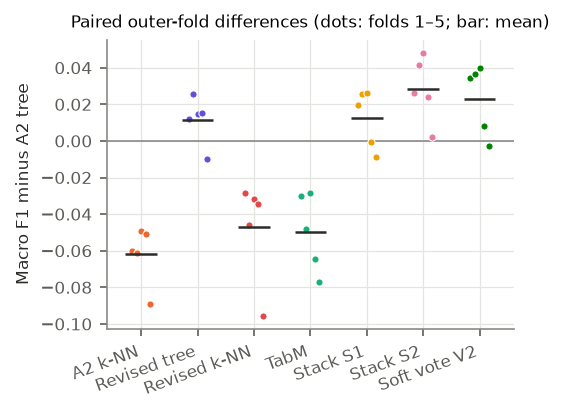

In [17]:
MODEL_NAMES = {
    "tree": "A2 tree", "knn": "A2 k-NN", "tree_r": "Revised tree", "knn_r": "Revised k-NN",
    "tabm": "TabM", "S1": "Stack S1", "S2": "Stack S2", "V2": "Soft vote V2",
}
MODEL_COLORS = dict(zip(MODEL_NAMES, ["#2a78d6", "#eb6834", "#6250d6", "#e34948", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 300, "font.size": 8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": "#e4e4e1", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8a86", "axes.labelcolor": "#2b2b29", "xtick.color": "#5c5c58", "ytick.color": "#5c5c58",
})


def save(fig, name):
    for suffix in ("pdf", "png"):
        fig.savefig(OUTPUT_DIR / f"ass4_{name}.{suffix}", bbox_inches="tight")


METRICS = {
    "macro_f1": lambda truth, pred: f1_score(truth, pred, average="macro"),
    "balanced_accuracy": balanced_accuracy_score,
    "accuracy": accuracy_score,
}
predictions = {key: predict_labels(proba) for key, proba in test_proba.items()}
fold_metrics = pd.DataFrame([
    {"model": model, "outer_fold": fold, **{name: score(y.loc[pred.index], pred) for name, score in METRICS.items()}}
    for (model, fold), pred in predictions.items()
])
fold_metrics.to_csv(OUTPUT_DIR / "ass4_fold_metrics.csv", index=False)
summary = fold_metrics.groupby("model")[list(METRICS)].agg(["mean", "std"]).reindex(list(MODEL_NAMES))
summary.index = summary.index.map(MODEL_NAMES)
summary.to_csv(OUTPUT_DIR / "ass4_summary.csv")
display(summary.round(4))

macro_by_fold = fold_metrics.pivot(index="outer_fold", columns="model", values="macro_f1")


def paired_comparison(model, reference):
    """Paired macro-F1 differences over the outer folds with a Wilcoxon and a corrected t-test."""
    difference = macro_by_fold[model] - macro_by_fold[reference]
    # Nadeau and Bengio: inflate the variance by n_test / n_train = 1 / (K - 1) for overlapping training sets.
    t = difference.mean() / np.sqrt((1 / len(difference) + 1 / (OUTER_FOLDS - 1)) * difference.var())
    return {
        "comparison": f"{MODEL_NAMES[model]} − {MODEL_NAMES[reference]}",
        "mean_difference": difference.mean(),
        "std": difference.std(),
        **{f"fold_{fold}": value for fold, value in difference.items()},
        "wilcoxon_p": stats.wilcoxon(difference).pvalue,
        "corrected_t_p": 2 * stats.t.sf(abs(t), len(difference) - 1),
    }


COMPARISONS = [(model, "tree") for model in ("knn", "tree_r", "knn_r", "tabm", "S1", "S2", "V2")] + [
    ("knn_r", "knn"), ("S2", "V2"), ("S2", "S1"), ("S2", "tabm"),
]
paired = pd.DataFrame([paired_comparison(*pair) for pair in COMPARISONS]).set_index("comparison")
# Holm adjustment across the eleven corrected-test comparisons.
ordered = paired["corrected_t_p"].sort_values().index
paired.loc[ordered, "holm_p"] = np.maximum.accumulate(np.minimum(
    1, paired.loc[ordered, "corrected_t_p"].to_numpy() * np.arange(len(paired), 0, -1)
))
paired.to_csv(OUTPUT_DIR / "ass4_paired_tests.csv")
display(paired.round(4))

others = [model for model in MODEL_NAMES if model != "tree"]
fig, ax = plt.subplots(figsize=(3.5, 2.5))
jitter = np.linspace(-0.16, 0.16, OUTER_FOLDS)
for position, model in enumerate(others):
    difference = macro_by_fold[model] - macro_by_fold["tree"]
    ax.scatter(position + jitter, difference, s=12, color=MODEL_COLORS[model], edgecolor="white", linewidth=0.5, zorder=3)
    ax.hlines(difference.mean(), position - 0.28, position + 0.28, color="#2b2b29", linewidth=1.2, zorder=4)
ax.axhline(0, color="#8a8a86", linewidth=0.8)
ax.set_xticks(range(len(others)), [MODEL_NAMES[model] for model in others], rotation=20, ha="right")
ax.set_ylabel("Macro F1 minus A2 tree")
ax.set_title("Paired outer-fold differences (dots: folds 1–5; bar: mean)", fontsize=8)
save(fig, "paired_differences")
plt.show()

**Finding.** S2 had the highest macro F1, 0.603 ± 0.010 against 0.575 ± 0.017 for the baseline
tree, higher on all five folds (Holm p = 0.455). `ass4_paired_tests.csv` feeds report Table VI
and Figure 1.

## 5.2 Per-class results and conflicting labels (Q9)

Computes pooled per-class metrics and confusion matrices.

,A2 tree,A2 k-NN,Revised tree,Revised k-NN,TabM,Stack S1,Stack S2,Soft vote V2
attack_class,,,,,,,,
Normal,0.909,0.900,0.856,0.904,0.918,0.917,0.922,0.916
Reconnaissance,0.831,0.713,0.825,0.757,0.832,0.835,0.840,0.832
Backdoor,0.152,0.095,0.160,0.106,0.160,0.166,0.178,0.233
DoS,0.311,0.403,0.472,0.419,0.102,0.303,0.309,0.433
Exploits,0.716,0.683,0.645,0.697,0.738,0.729,0.738,0.719
Analysis,0.104,0.155,0.155,0.109,0.061,0.109,0.104,0.138
Fuzzers,0.606,0.552,0.616,0.563,0.597,0.617,0.631,0.650
Worms,0.598,0.288,0.561,0.275,0.260,0.580,0.661,0.440
Shellcode,0.615,0.349,0.582,0.476,0.602,0.633,0.660,0.631


,a2_tree,best_model,best_f1,best_ensemble,best_ensemble_f1,gain
attack_class,,,,,,
Backdoor,0.152,Soft vote V2,0.233,Soft vote V2,0.233,0.080
DoS,0.311,Revised tree,0.472,Soft vote V2,0.433,0.161
Analysis,0.104,A2 k-NN,0.155,Soft vote V2,0.138,0.051


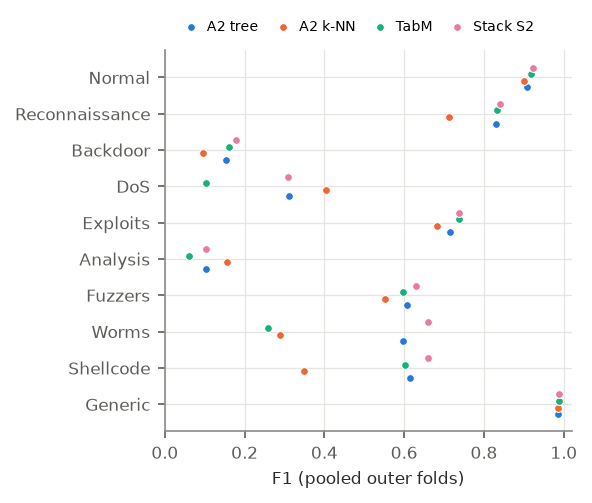

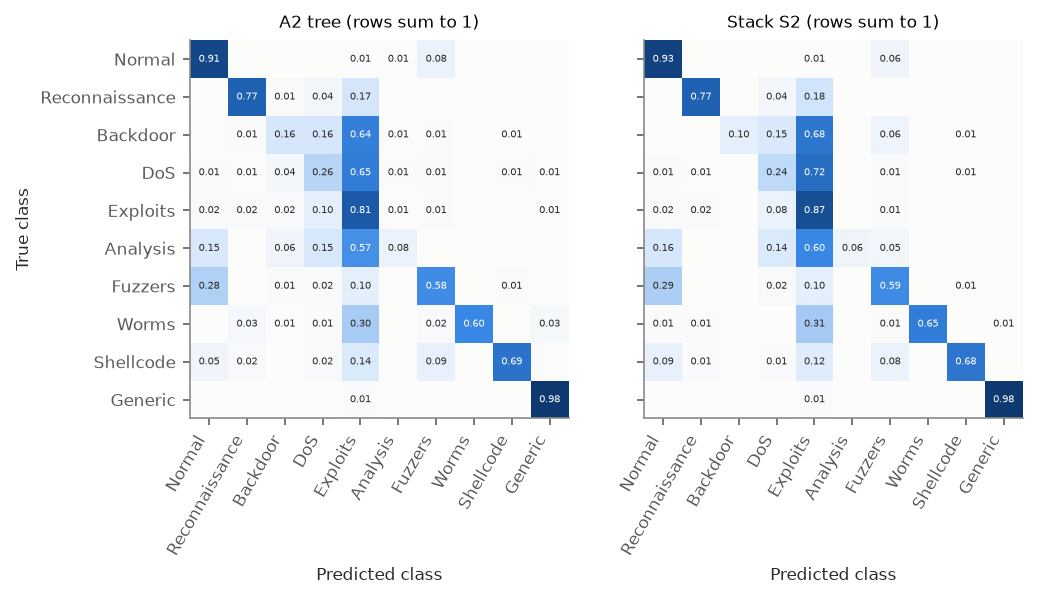

In [18]:
pooled = {model: pd.concat([predictions[model, fold] for fold in FOLDS]) for model in MODEL_NAMES}
per_class = pd.DataFrame(
    {MODEL_NAMES[model]: f1_score(y.loc[pred.index], pred, labels=CLASS_ORDER, average=None) for model, pred in pooled.items()},
    index=CLASS_ORDER,
)
per_class.index.name = "attack_class"
per_class.to_csv(OUTPUT_DIR / "ass4_per_class_f1.csv")
display(per_class.round(3))

class_metric_rows = []
for model, pred in pooled.items():
    scores = precision_recall_fscore_support(
        y.loc[pred.index], pred, labels=CLASS_ORDER, zero_division=0
    )
    for name, precision, recall, score, support in zip(CLASS_ORDER, *scores):
        class_metric_rows.append({
            "model": MODEL_NAMES[model], "attack_class": name,
            "precision": precision, "recall": recall, "f1": score, "support": support,
        })
per_class_metrics = pd.DataFrame(class_metric_rows)
per_class_metrics.to_csv(OUTPUT_DIR / "ass4_per_class_metrics.csv", index=False)

HARD_CLASSES = ["Backdoor", "DoS", "Analysis"]
ensembles = [MODEL_NAMES[model] for model in ("tabm", "S1", "S2", "V2")]
conflict_class_comparison = pd.DataFrame({
    "a2_tree": per_class.loc[HARD_CLASSES, "A2 tree"],
    "best_model": per_class.loc[HARD_CLASSES].idxmax(axis=1),
    "best_f1": per_class.loc[HARD_CLASSES].max(axis=1),
    "best_ensemble": per_class.loc[HARD_CLASSES, ensembles].idxmax(axis=1),
    "best_ensemble_f1": per_class.loc[HARD_CLASSES, ensembles].max(axis=1),
})
conflict_class_comparison["gain"] = conflict_class_comparison["best_f1"] - conflict_class_comparison["a2_tree"]
conflict_class_comparison.to_csv(OUTPUT_DIR / "ass4_conflict_class_comparison.csv")
display(conflict_class_comparison.round(3))

shown = ["tree", "knn", "tabm", "S2"]
fig, ax = plt.subplots(figsize=(3.5, 3.3))
positions = np.arange(len(CLASS_ORDER))[::-1]
for offset, model in zip(np.linspace(-0.27, 0.27, len(shown)), shown):
    ax.scatter(per_class[MODEL_NAMES[model]], positions + offset, s=14, color=MODEL_COLORS[model],
               edgecolor="white", linewidth=0.5, label=MODEL_NAMES[model], zorder=3)
ax.set_yticks(positions, CLASS_ORDER)
ax.set_xlim(0, 1.02)
ax.set_xlabel("F1 (pooled outer folds)")
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=4, frameon=False, fontsize=6.5, handletextpad=0.2, columnspacing=0.8)
save(fig, "per_class_f1")
plt.show()

best_ensemble = summary.loc[ensembles, ("macro_f1", "mean")].idxmax()
best_key = next(model for model, name in MODEL_NAMES.items() if name == best_ensemble)
blues = LinearSegmentedColormap.from_list("blues", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, axes = plt.subplots(1, 2, figsize=(7.16, 3.3), sharey=True)
for ax, model in zip(axes, ("tree", best_key)):
    matrix = confusion_matrix(y.loc[pooled[model].index], pooled[model], labels=CLASS_ORDER, normalize="true")
    ax.imshow(matrix, cmap=blues, vmin=0, vmax=1)
    for (row, col), value in np.ndenumerate(matrix):
        if value >= 0.005:
            ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=5,
                    color="white" if value > 0.55 else "#2b2b29")
    ax.set_xticks(range(len(CLASS_ORDER)), CLASS_ORDER, rotation=60, ha="right")
    ax.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
    ax.set_xlabel("Predicted class")
    ax.set_title(f"{MODEL_NAMES[model]} (rows sum to 1)", fontsize=8)
    ax.grid(False)
axes[0].set_ylabel("True class")
save(fig, "confusion_matrices")
plt.show()


**Finding (Q9).** The revised tree was best on DoS (F1 0.472) and the soft vote on Backdoor
(0.233). Report Tables VII–VIII and Figure 2.

## 5.3 TabM tuning questions (Q1–Q4)

Summarises inner macro F1 of the tuning variants over the five outer folds.

val_macro_f1         mean_member_f1           epochs           seconds  \
           mean     std           mean     std     mean     std      mean   
k                                                                           
1        0.5339  0.0092         0.5339  0.0092  15.3333  7.6449  167.2135   
4        0.5383  0.0080         0.5349  0.0075  16.1333  5.5508  110.9544   
8        0.5388  0.0113         0.5336  0.0100  16.1333  6.0992   91.4672   
32       0.5423  0.0037         0.5349  0.0043  19.6000  6.7223  189.3324   

             
        std  
k            
1   80.4325  
4   49.8061  
8   27.5510  
32  80.8453

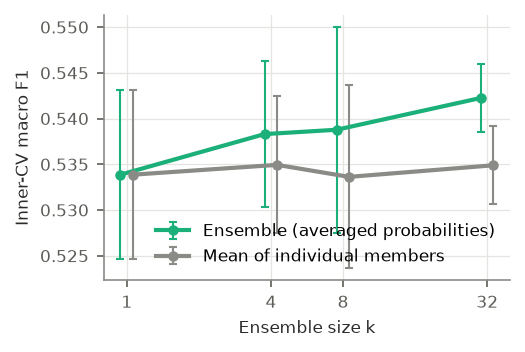

,unweighted,class_weighted,difference
Normal,0.914,0.847,-0.067
Reconnaissance,0.827,0.818,-0.008
Backdoor,0.140,0.162,0.022
DoS,0.361,0.468,0.107
Exploits,0.716,0.596,-0.120
Analysis,0.067,0.170,0.103
Fuzzers,0.578,0.604,0.026
Worms,0.257,0.093,-0.164
Shellcode,0.576,0.413,-0.163
Generic,0.986,0.986,-0.000


,shared,distinct,shared_member_f1,distinct_member_f1,difference
outer_fold,,,,,
1,0.5361,0.5262,0.5306,0.5235,-0.0099
2,0.5439,0.5385,0.5301,0.5299,-0.0054
3,0.5458,0.5319,0.5382,0.5274,-0.0139
4,0.5439,0.5323,0.5391,0.5307,-0.0116
5,0.5416,0.5392,0.5364,0.5309,-0.0024


val_macro_f1   epochs
factor   value                         
d_block  256.000        0.5244  21.6556
         512.000        0.5310  17.1500
n_blocks 2.000          0.5257  19.0222
         3.000          0.5296  19.7833
dropout  0.000          0.5334  16.8667
         0.100          0.5273  17.9833
         0.200          0.5222  23.3583
lr       0.001          0.5257  21.3944
         0.002          0.5296  17.4111

In [19]:
capacity = tabm_tuning[tabm_tuning["question"] == "Q4 capacity"]
stage1_best = capacity.loc[capacity.groupby("outer_fold")["val_macro_f1"].idxmax()]
by_question = {question: group.set_index("outer_fold") for question, group in tabm_tuning.groupby("question")}

k_sweep = (
    pd.concat([stage1_best, by_question["Q1 ensemble size"].reset_index()])
    .groupby("k")[["val_macro_f1", "mean_member_f1", "epochs", "seconds"]]
    .agg(["mean", "std"])
)
k_sweep.to_csv(OUTPUT_DIR / "ass4_q1_k_sweep.csv")
display(k_sweep.round(4))

fig, ax = plt.subplots(figsize=(3.5, 2.3))
for column, label, color, dodge in (
    ("val_macro_f1", "Ensemble (averaged probabilities)", MODEL_COLORS["tabm"], 0.94),
    ("mean_member_f1", "Mean of individual members", "#8a8a86", 1.06),
):
    ax.errorbar(k_sweep.index * dodge, k_sweep[column, "mean"], yerr=k_sweep[column, "std"], marker="o", markersize=4,
                linewidth=2, elinewidth=1, capsize=2, color=color, label=label)
ax.set_xscale("log", base=2)
ax.set_xticks(k_sweep.index, [str(k) for k in k_sweep.index])
ax.set_xlim(0.8, 40)
ax.set_xlabel("Ensemble size k")
ax.set_ylabel("Inner-CV macro F1")
ax.legend(frameon=False, loc="lower right")
save(fig, "tabm_k_sweep")
plt.show()

class_columns = [f"val_f1_{name}" for name in CLASS_ORDER]
reference = stage1_best.set_index("outer_fold")
class_weighting = pd.DataFrame({
    "unweighted": reference[class_columns].mean().to_numpy(),
    "class_weighted": by_question["Q2 class weights"][class_columns].mean().to_numpy(),
}, index=CLASS_ORDER)
class_weighting.loc["macro F1"] = [reference["val_macro_f1"].mean(), by_question["Q2 class weights"]["val_macro_f1"].mean()]
class_weighting["difference"] = class_weighting["class_weighted"] - class_weighting["unweighted"]
class_weighting.to_csv(OUTPUT_DIR / "ass4_q2_class_weights.csv")
display(class_weighting.round(3))

batches = pd.DataFrame({
    "shared": reference["val_macro_f1"],
    "distinct": by_question["Q3 distinct batches"]["val_macro_f1"],
    "shared_member_f1": reference["mean_member_f1"],
    "distinct_member_f1": by_question["Q3 distinct batches"]["mean_member_f1"],
})
batches["difference"] = batches["distinct"] - batches["shared"]
batches.to_csv(OUTPUT_DIR / "ass4_q3_batches.csv")
display(batches.round(4))

capacity_effects = pd.concat({
    factor: capacity.groupby(factor)[["val_macro_f1", "epochs"]].mean()
    for factor in ("d_block", "n_blocks", "dropout", "lr")
}, names=["factor", "value"])
capacity_effects.to_csv(OUTPUT_DIR / "ass4_q4_capacity_effects.csv")
display(capacity_effects.round(4))

**Findings.** Q1: 0.534 at one member, 0.542 at 32 (Figure 3). Q2: balanced weights −0.027
(Table IX). Q3: distinct batches −0.009. Q4: no factor above 0.012 (Table X).

## 5.4 Stacking questions (Q5–Q8)

Measures base-learner diversity and the inner score of each meta-feature representation.

In [20]:
diversity_rows = []
for a, b in itertools.combinations(STACKS["S2"], 2):
    for fold in FOLDS:
        truth = y.loc[predictions[a, fold].index]
        error_a, error_b = predictions[a, fold].ne(truth), predictions[b, fold].ne(truth)
        diversity_rows.append({
            "pair": f"{MODEL_NAMES[a]} / {MODEL_NAMES[b]}",
            "error_correlation": np.corrcoef(error_a, error_b)[0, 1],
            "disagreement": predictions[a, fold].ne(predictions[b, fold]).mean(),
            "both_wrong": (error_a & error_b).mean(),
        })
diversity = pd.DataFrame(diversity_rows).groupby("pair").agg(["mean", "std"])
diversity.to_csv(OUTPUT_DIR / "ass4_q6_diversity.csv")
display(diversity.round(3))

meta_search = pd.concat(meta_search_rows, ignore_index=True)
meta_search["representation"] = meta_search["params"].map(lambda params: params["features__kw_args"]["kind"])
meta_search.assign(params=meta_search["params"].astype(str)).to_csv(OUTPUT_DIR / "ass4_meta_tuning.csv", index=False)
representation = (
    meta_search.groupby(["stack", "outer_fold", "representation"])["mean_test_score"].max()
    .groupby(["stack", "representation"]).agg(["mean", "std"]).unstack("stack")
)
representation.to_csv(OUTPUT_DIR / "ass4_q8_representation.csv")
display(representation.round(4))
selected_meta = (
    meta_search[meta_search["rank_test_score"] == 1].drop_duplicates(["stack", "outer_fold"])
    .assign(C=lambda frame: frame["params"].map(lambda params: params["model__C"]),
            class_weight=lambda frame: frame["params"].map(lambda params: params["model__class_weight"] or "none"))
    .set_index(["stack", "outer_fold"])[["representation", "C", "class_weight", "mean_test_score"]]
)
selected_meta.to_csv(OUTPUT_DIR / "ass4_meta_selected.csv")
display(selected_meta)

error_correlation        disagreement        \
                                         mean    std         mean   std   
pair                                                                      
Revised k-NN / Revised tree             0.460  0.027        0.238  0.01   
Revised k-NN / TabM                     0.565  0.047        0.163  0.02   
Revised tree / TabM                     0.307  0.036        0.285  0.01   

                            both_wrong         
                                  mean    std  
pair                                           
Revised k-NN / Revised tree      0.125  0.005  
Revised k-NN / TabM              0.120  0.006  
Revised tree / TabM              0.092  0.006

mean             std        
stack               S1      S2      S1      S2
representation                                
log_proba       0.5606  0.5773  0.0047  0.0044
one_hot         0.5669  0.5589  0.0099  0.0086
proba           0.5777  0.5904  0.0056  0.0051

representation      C class_weight  mean_test_score
stack outer_fold                                                    
S1    1                   proba   0.10         none         0.571827
      2                   proba  10.00         none         0.584541
      3                   proba  10.00         none         0.574270
      4                   proba   0.01         none         0.575133
      5                   proba   0.10         none         0.582720
S2    1                   proba   0.10         none         0.584726
      2                   proba   0.10         none         0.597397
      3                   proba   1.00         none         0.592894
      4                   proba   1.00         none         0.586451
      5                   proba   0.01         none         0.590332

**Findings.** S2 exceeded V2 by 0.005 (Q5) and S1 by 0.016 (Q6). Tree–TabM error correlation was
lowest, 0.307 (Table XI). Probabilities won all ten stack–fold cases (Q8, Table XII).

**Own-class coefficients (Q7).** Plots the S2 own-class coefficients.

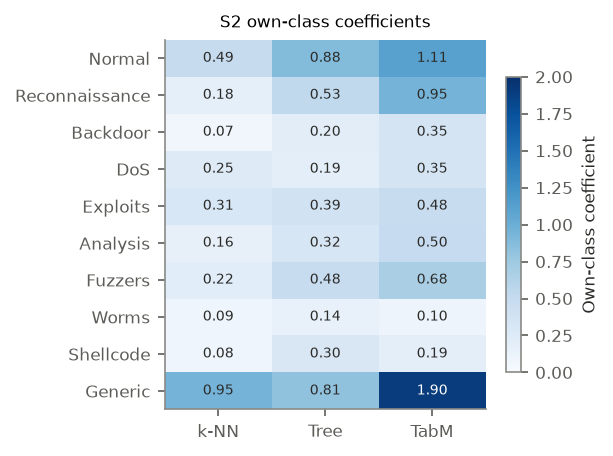

In [21]:
own_class = pd.DataFrame(
    {
        MODEL_NAMES[learner]: [
            np.mean([meta_coefficients["S2", fold].loc[name, f"{learner}:{name}"] for fold in FOLDS]) for name in CLASS_ORDER
        ]
        for learner in STACKS["S2"]
    },
    index=CLASS_ORDER,
)
own_class.to_csv(OUTPUT_DIR / "ass4_q7_meta_coefficients.csv")

limit = np.abs(own_class.to_numpy()).max()
fig, ax = plt.subplots(figsize=(3.45, 3.2))
image = ax.imshow(own_class, cmap="Blues", vmin=0, vmax=2, aspect="auto")
for (row, col), value in np.ndenumerate(own_class.to_numpy()):
    ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=6.5,
            color="white" if abs(value) > 0.6 * limit else "#2b2b29")
ax.set_xticks(range(own_class.shape[1]), ["k-NN", "Tree", "TabM"])
ax.set_yticks(range(len(CLASS_ORDER)), CLASS_ORDER)
ax.grid(False)
fig.colorbar(image, ax=ax, shrink=0.8, label="Own-class coefficient")
ax.set_title("S2 own-class coefficients", fontsize=8)
save(fig, "meta_coefficients")
plt.show()

**Finding (Q7).** TabM had the largest coefficient on eight classes, the tree on Worms and
Shellcode (Figure 4).

## 5.5 Computational cost

Tabulates seconds per outer fold (report Table XIII).

In [22]:
cost = pd.Series(oof_seconds).groupby(level=0).mean().rename("oof_seconds_per_fold").to_frame()
cost["tuning_seconds_per_fold"] = pd.Series({
    "tree_r": revised_tuning["tree"].groupby("outer_fold")["seconds"].first().mean(),
    "knn_r": revised_tuning["knn"].groupby("outer_fold")["seconds"].first().mean(),
    "tabm": tabm_tuning.groupby("outer_fold")["seconds"].sum().mean(),
})
cost.index = cost.index.map(MODEL_NAMES)
cost.to_csv(OUTPUT_DIR / "ass4_cost.csv")
display(cost.round(0))

,oof_seconds_per_fold,tuning_seconds_per_fold
A2 k-NN,676.0,NaN
Revised k-NN,216.0,4617.0
TabM,405.0,4977.0
A2 tree,19.0,NaN
Revised tree,16.0,185.0


**Finding.** The k-NN and TabM searches shared the GPU, so their durations overlap. Each alone
took over 200 times the 19 s of the four baseline tree fits.

# Summary

The report answers Q1–Q9 in Section V.